# CNN Klasifikasi Serangga (GBIF Insect Identification) — Transfer Learning EfficientNetB0

Versi ini dioptimalkan untuk **Google Colab**: dataset diunduh/diekstrak ke disk lokal sesi
runtime (`/content/...`) agar I/O cepat, sementara seluruh hasil (checkpoint, riwayat, model,
metadata) disimpan ke **Google Drive** agar aman dari putusnya sesi runtime.

Pipeline: setup & GPU -> konfigurasi -> mount Drive & ambil dataset Kaggle -> split & balancing ->
`tf.data` pipeline -> arsitektur **EfficientNetB0** (feature extraction + fine-tuning) ->
training & resume aman -> evaluasi test -> simpan model & metadata.

**Cara pakai**
- Jalankan dari atas ke bawah secara berurutan.
- Semua hyperparameter ada di satu sel **Konfigurasi** (bagian 2) — ubah di sana saja.
- **Alur transfer learning dua tahap** (lihat bagian 11 & 12 untuk detail):
  1. **Feature extraction**: `FREEZE_BACKBONE=True`, `FINE_TUNE_ENABLED=False` (default) — hanya head yang dilatih.
  2. **Fine-tuning**: setelah fase 1 konvergen, ubah `FINE_TUNE_ENABLED=True` di Konfigurasi, lalu jalankan
     ulang sel training. Backbone dibuka sebagian (`FINE_TUNE_AT`) dengan learning rate kecil (`FINE_TUNE_LR`).
- Training aman di-*resume*: cukup jalankan ulang sel training, `initial_epoch` otomatis dibaca dari
  `history_log.json`, tidak perlu di-hardcode manual.

## 1. Setup Environment & GPU
Notebook ini dioptimalkan untuk **Google Colab** (GPU + Google Drive + disk lokal `/content`).

In [ ]:
import os, sys, json, random, shutil, subprocess
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

IN_COLAB = "google.colab" in sys.modules

print("TensorFlow:", tf.__version__)
print("GPU terdeteksi:", tf.config.list_physical_devices("GPU") or "TIDAK ADA (aktifkan GPU di Runtime > Change runtime type)")
if not IN_COLAB:
    print("PERINGATAN: notebook ini dioptimalkan untuk Google Colab (I/O lokal /content + output ke Google Drive).")

TensorFlow: 2.21.0
GPU terdeteksi: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Konfigurasi (Hyperparameter Terpusat)
Semua pengaturan penting dikumpulkan di satu tempat, dikelompokkan per kategori:
- `data`: ukuran gambar, batch, jumlah kelas, seed, rasio split, ambang minimum sampel per kelas.
- `balance`: penyeimbangan data train (`TARGET_PER_CLASS`, metode).
- `augment`: parameter augmentasi gambar (aktif hanya saat training).
- `transfer_learning`: backbone EfficientNetB0 & pengaturan freeze/fine-tuning.
- `model`: ukuran head klasifikasi (unit dense & dropout) yang ditambahkan di atas backbone.
- `train`: learning rate, epoch, callback, class weight.

`NUM_CLASSES = None` berarti memakai semua kelas yang tersedia.
`SELECTION_MODE`: `"top"` = kelas dgn gambar terbanyak (disarankan), `"first"` = urut kode GBIF, `"random"` = acak.
`IMG_SIZE` default `224` mengikuti resolusi native EfficientNetB0.

In [ ]:
CONFIG = {
    "kaggle_dataset": "kmldas/insect-identification-from-habitus-images",

    "data": {
        "IMG_SIZE": 224,                # resolusi native EfficientNetB0
        "BATCH_SIZE": 32,
        "NUM_CLASSES": 50,              # None = semua kelas
        "SEED": 42,
        "SPLIT": (0.70, 0.15, 0.15),    # train, val, test (harus berjumlah 1.0)
        "MIN_SAMPLES_PER_CLASS": 20,    # kelas dengan gambar lebih sedikit dari ini diabaikan
        "SELECTION_MODE": "top",        # "top" | "first" | "random"
    },

    "balance": {
        "ENABLED": True,
        "TARGET_PER_CLASS": 150,        # jumlah sampel target per kelas DI DATA TRAIN SAJA
        "METHOD": "both",               # "undersample" | "oversample" | "both"
    },

    "augment": {
        "FLIP": "horizontal",
        "ROTATION": 0.10,
        "ZOOM": 0.10,
        "TRANSLATION": 0.10,
        "CONTRAST": 0.10,
    },

    "transfer_learning": {
        "BACKBONE": "EfficientNetB0",
        "WEIGHTS": "imagenet",
        "FREEZE_BACKBONE": True,        # True = tahap feature extraction (head saja yang dilatih)
        "FINE_TUNE_ENABLED": False,     # aktifkan True utk tahap fine-tuning lanjutan
        "FINE_TUNE_AT": 20,             # jumlah layer dari AKHIR backbone yang dibuka saat fine-tuning
        "FINE_TUNE_LR": 1e-4,           # learning rate kecil khusus fine-tuning
    },

    "model": {
        "HEAD_UNITS": 256,              # unit dense pada head klasifikasi
        "HEAD_DROPOUT": 0.30,
    },

    "train": {
        "LEARNING_RATE": 1e-3,          # dipakai saat FINE_TUNE_ENABLED = False
        "EPOCHS": 60,                   # epoch TARGET (bukan jumlah epoch tambahan, lihat bagian 12)
        "USE_CLASS_WEIGHT": False,      # bisa dikombinasikan dengan balancing bila perlu
        "EARLY_STOPPING_PATIENCE": 12,
        "REDUCE_LR_FACTOR": 0.5,
        "REDUCE_LR_PATIENCE": 4,
        "REDUCE_LR_MIN_LR": 1e-6,
    },
}

assert abs(sum(CONFIG["data"]["SPLIT"]) - 1.0) < 1e-6, "SPLIT harus berjumlah 1.0"

random.seed(CONFIG["data"]["SEED"])
np.random.seed(CONFIG["data"]["SEED"])
tf.random.set_seed(CONFIG["data"]["SEED"])

print(json.dumps(CONFIG, indent=2))

{
  "kaggle_dataset": "kmldas/insect-identification-from-habitus-images",
  "data": {
    "IMG_SIZE": 224,
    "BATCH_SIZE": 32,
    "NUM_CLASSES": 50,
    "SEED": 42,
    "SPLIT": [
      0.7,
      0.15,
      0.15
    ],
    "MIN_SAMPLES_PER_CLASS": 20,
    "SELECTION_MODE": "top"
  },
  "balance": {
    "ENABLED": true,
    "TARGET_PER_CLASS": 150,
    "METHOD": "both"
  },
  "augment": {
    "FLIP": "horizontal",
    "ROTATION": 0.1,
    "ZOOM": 0.1,
    "TRANSLATION": 0.1,
    "CONTRAST": 0.1
  },
  "transfer_learning": {
    "BACKBONE": "EfficientNetB0",
    "WEIGHTS": "imagenet",
    "FREEZE_BACKBONE": true,
    "FINE_TUNE_ENABLED": false,
    "FINE_TUNE_AT": 20,
    "FINE_TUNE_LR": 0.0001
  },
  "model": {
    "HEAD_UNITS": 256,
    "HEAD_DROPOUT": 0.3
  },
  "train": {
    "LEARNING_RATE": 0.001,
    "EPOCHS": 60,
    "USE_CLASS_WEIGHT": false,
    "EARLY_STOPPING_PATIENCE": 12,
    "REDUCE_LR_FACTOR": 0.5,
    "REDUCE_LR_PATIENCE": 4,
    "REDUCE_LR_MIN_LR": 1e-06
  }
}


## 3. Mount Google Drive & Direktori Kerja
- Dataset mentah disimpan di **disk lokal runtime** `/content/kaggle_raw` (bukan Drive) agar I/O cepat
  dan tidak memenuhi kuota Google Drive dengan file mentah.
- Seluruh output training (checkpoint, riwayat, model final, metadata) disimpan ke **Google Drive**
  di `OUTPUT_DIR`, sehingga aman walau runtime Colab terputus/di-reset.

In [ ]:
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
else:
    raise RuntimeError(
        "Notebook ini memerlukan Google Colab (Google Drive + disk lokal /content). "
        "Jalankan di colab.research.google.com."
    )

OUTPUT_DIR = "/content/drive/MyDrive/insect_cnn_effnet_output"
RAW_DATA_DIR = "/content/kaggle_raw"

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(RAW_DATA_DIR, exist_ok=True)

LAST_CKPT = os.path.join(OUTPUT_DIR, "last_checkpoint.keras")        # disimpan tiap akhir epoch (utk resume)
BEST_CKPT = os.path.join(OUTPUT_DIR, "best_checkpoint.keras")        # disimpan saat val terbaik (utk evaluasi/inference)
HISTORY_PATH = os.path.join(OUTPUT_DIR, "history_log.json")          # riwayat training akumulatif lintas sesi
CLASS_NAMES_PATH = os.path.join(OUTPUT_DIR, "class_names.json")      # mapping indeks -> kode GBIF

print("Dataset lokal (sementara):", RAW_DATA_DIR)
print("Output permanen (Google Drive):", OUTPUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset lokal (sementara): /content/kaggle_raw
Output permanen (Google Drive): /content/drive/MyDrive/insect_cnn_effnet_output


## 4. Ambil Dataset dari Kaggle ke Disk Lokal
- Diunduh & diekstrak langsung ke `/content/kaggle_raw` (disk lokal sesi runtime) agar pembacaan
  gambar saat training cepat.
- Jika folder lokal **sudah berisi data pada sesi yang sama**, unduh/ekstrak ulang **dilewati** secara otomatis.
- Kredensial Kaggle dicari dari (urut prioritas): `~/.kaggle/kaggle.json` yang sudah ada ->
  environment variable `KAGGLE_USERNAME`/`KAGGLE_KEY` -> **Colab Secrets**.

In [ ]:
KAGGLE_DATASET = CONFIG["kaggle_dataset"]

def setup_kaggle_credentials():
    # Siapkan kredensial Kaggle dari kaggle.json, env var, atau Colab Secrets.
    kaggle_cfg = os.path.expanduser("~/.kaggle/kaggle.json")
    if os.path.exists(kaggle_cfg) or (os.environ.get("KAGGLE_USERNAME") and os.environ.get("KAGGLE_KEY")):
        return
    try:
        from google.colab import userdata
        os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
        os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
        return
    except Exception:
        pass
    raise RuntimeError(
        "Kredensial Kaggle tidak ditemukan. Set Colab Secrets (KAGGLE_USERNAME, KAGGLE_KEY), "
        "environment variable, atau siapkan ~/.kaggle/kaggle.json."
    )

def find_dataset_root(base):
    # Cari folder yang berisi banyak subfolder bernama angka (kode GBIF), mis. database/4470555.
    best, best_n = None, 0
    for dirpath, dirnames, _ in os.walk(base):
        n = sum(d.isdigit() for d in dirnames)
        if n > best_n:
            best, best_n = dirpath, n
    return best, best_n

if os.listdir(RAW_DATA_DIR):
    print(f"Dataset lokal sudah ada di {RAW_DATA_DIR} (sesi ini) -> lewati unduh/ekstrak ulang.")
else:
    setup_kaggle_credentials()
    print(f"Mengunduh & mengekstrak dataset Kaggle ke {RAW_DATA_DIR} ...")
    subprocess.run(["kaggle", "datasets", "download", "-d", KAGGLE_DATASET,
                    "-p", RAW_DATA_DIR, "--unzip", "-q"], check=True)
    print("Selesai.")

SEARCH_DIR = RAW_DATA_DIR

Mengunduh & mengekstrak dataset Kaggle ke /content/kaggle_raw ...
Selesai.


## 5. Deteksi Folder Dataset & Daftar Kelas

In [ ]:
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp")

DATASET_ROOT, n_dirs = find_dataset_root(SEARCH_DIR)
assert DATASET_ROOT is not None, "Folder kelas (nama angka/kode GBIF) tidak ditemukan. Cek SEARCH_DIR."
print(f"Dataset root: {DATASET_ROOT}  ({n_dirs} folder kelas)")

class_files = {}
for cls in sorted(d for d in os.listdir(DATASET_ROOT) if d.isdigit()):
    files_ = [os.path.join(dp, f) for dp, _, fn in os.walk(os.path.join(DATASET_ROOT, cls))
              for f in fn if f.lower().endswith(IMG_EXT)]
    if files_:
        class_files[cls] = files_

print(f"Total kelas terdeteksi: {len(class_files)}")

Dataset root: /content/kaggle_raw/database  (291 folder kelas)
Total kelas terdeteksi: 291


## 6. Pilih Subset Kelas

Kelas memenuhi minimum 20 gambar: 291
Kelas dipakai: 50 | total gambar: 24234 | min/maks per kelas: 358/888


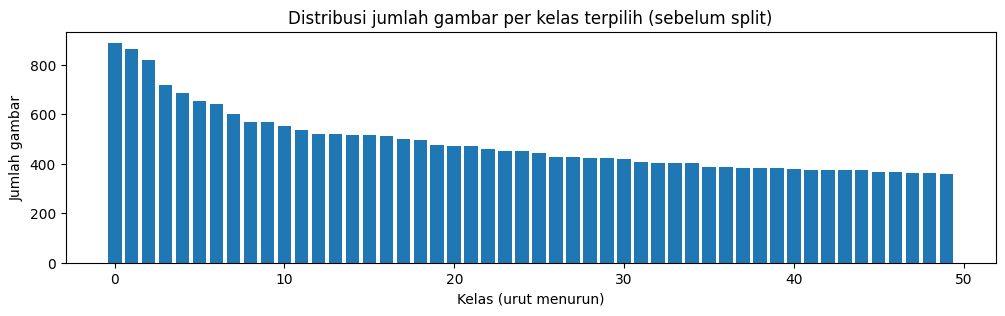

In [ ]:
cfg = CONFIG["data"]

eligible = {c: f for c, f in class_files.items() if len(f) >= cfg["MIN_SAMPLES_PER_CLASS"]}
print(f"Kelas memenuhi minimum {cfg['MIN_SAMPLES_PER_CLASS']} gambar: {len(eligible)}")

if cfg["SELECTION_MODE"] == "top":
    ordered = sorted(eligible, key=lambda c: len(eligible[c]), reverse=True)
elif cfg["SELECTION_MODE"] == "first":
    ordered = sorted(eligible, key=int)
else:
    ordered = list(eligible); random.shuffle(ordered)

selected = ordered if cfg["NUM_CLASSES"] is None else ordered[:cfg["NUM_CLASSES"]]
selected_files = {c: eligible[c] for c in sorted(selected)}

sel_counts = [len(v) for v in selected_files.values()]
print(f"Kelas dipakai: {len(selected_files)} | total gambar: {sum(sel_counts)} "
      f"| min/maks per kelas: {min(sel_counts)}/{max(sel_counts)}")

plt.figure(figsize=(12, 3))
plt.bar(range(len(sel_counts)), sorted(sel_counts, reverse=True))
plt.title("Distribusi jumlah gambar per kelas terpilih (sebelum split)")
plt.xlabel("Kelas (urut menurun)"); plt.ylabel("Jumlah gambar")
plt.show()

## 7. Split Train / Val / Test (Stratified)
Split dilakukan langsung di level **daftar path file** (tanpa menyalin file secara fisik) agar
efisien dan mendukung balancing (oversampling) tanpa duplikasi file di disk.
*Stratified* = proporsi setiap kelas dijaga sama di ketiga subset.

In [ ]:
from sklearn.model_selection import train_test_split

paths, labels = [], []
for c, fl in selected_files.items():
    paths += fl; labels += [c] * len(fl)

split_ratio = cfg["SPLIT"]
p_train, p_tmp, y_train, y_tmp = train_test_split(
    paths, labels, test_size=1 - split_ratio[0], stratify=labels, random_state=cfg["SEED"])
p_val, p_test, y_val, y_test = train_test_split(
    p_tmp, y_tmp, test_size=split_ratio[2] / (split_ratio[1] + split_ratio[2]),
    stratify=y_tmp, random_state=cfg["SEED"])

print(f"Train: {len(p_train)} | Val: {len(p_val)} | Test: {len(p_test)}")

# Urutan indeks kelas TETAP (tidak berubah oleh balancing di bawah) -> konsisten utk inference
class_names = sorted(selected_files.keys())
cls_to_idx = {c: i for i, c in enumerate(class_names)}

Train: 16963 | Val: 3635 | Test: 3636


## 8. Penyeimbangan (Balancing) Data Train
Dilakukan **setelah** split dan **hanya pada data `train`**, agar tidak terjadi *data leakage*
ke `val`/`test` dan distribusi evaluasi tetap jujur/representatif.

Pendekatan (`CONFIG["balance"]["METHOD"]`):
- **Undersampling**: kelas dengan gambar > `TARGET_PER_CLASS` diambil sampel acak sejumlah target.
- **Oversampling**: kelas dengan gambar < `TARGET_PER_CLASS` diduplikasi acak (*with replacement*)
  hingga mencapai target.

Balancing: aktif (both) | target/kelas: 150
Train sebelum: 16963 gambar | sesudah: 7500 gambar


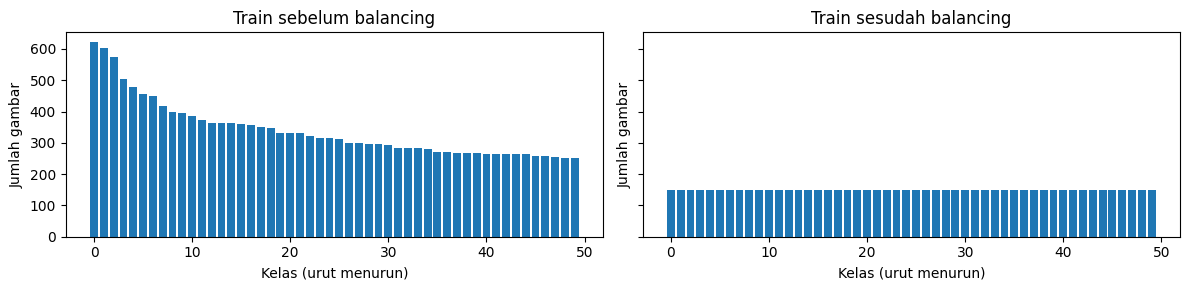

In [ ]:
bal = CONFIG["balance"]
rng = random.Random(cfg["SEED"])

def balance_train(paths, labels, target, method):
    by_class = {}
    for p, y in zip(paths, labels):
        by_class.setdefault(y, []).append(p)
    before = {c: len(v) for c, v in by_class.items()}

    out_paths, out_labels = [], []
    for c, plist in by_class.items():
        n = len(plist)
        if n > target and method in ("undersample", "both"):
            plist = rng.sample(plist, target)
        elif n < target and method in ("oversample", "both"):
            plist = plist + rng.choices(plist, k=target - n)
        out_paths += plist
        out_labels += [c] * len(plist)
    after = dict(Counter(out_labels))
    return out_paths, out_labels, before, after

if bal["ENABLED"]:
    p_train_bal, y_train_bal, dist_before, dist_after = balance_train(
        p_train, y_train, bal["TARGET_PER_CLASS"], bal["METHOD"])
else:
    p_train_bal, y_train_bal = p_train, y_train
    dist_before = dist_after = dict(Counter(y_train))

print(f"Balancing: {'aktif (' + bal['METHOD'] + ')' if bal['ENABLED'] else 'tidak aktif'} "
      f"| target/kelas: {bal['TARGET_PER_CLASS']}")
print(f"Train sebelum: {len(p_train)} gambar | sesudah: {len(p_train_bal)} gambar")

fig, ax = plt.subplots(1, 2, figsize=(12, 3), sharey=True)
ax[0].bar(range(len(dist_before)), sorted(dist_before.values(), reverse=True)); ax[0].set_title("Train sebelum balancing")
ax[1].bar(range(len(dist_after)), sorted(dist_after.values(), reverse=True)); ax[1].set_title("Train sesudah balancing")
for a in ax:
    a.set_xlabel("Kelas (urut menurun)"); a.set_ylabel("Jumlah gambar")
plt.tight_layout(); plt.show()

## 9. Pipeline `tf.data`
Dataset dibangun langsung dari daftar path file (bukan direktori fisik hasil *copy*), sehingga
oversampling cukup berupa path yang berulang tanpa menduplikasi file di disk.

**Skala piksel untuk EfficientNetB0**: setelah resize, gambar diproses dengan
`tf.keras.applications.efficientnet.preprocess_input` — fungsi ini diterapkan di sini (tf.data),
dan dipakai lagi dengan cara yang sama persis saat *inference* 1 gambar (bagian 18), sehingga
skalanya konsisten di semua tahap. **Tidak ada `Rescaling(1/255)`** yang dipakai di sini maupun
di dalam model, karena EfficientNetB0 (`weights="imagenet"`) sudah menyertakan layer normalisasi
bawaan di awal backbone-nya yang mengharapkan piksel mentah 0–255.

Aman untuk memori:
- `train_ds` **tidak** di-`.cache()` penuh (ukurannya bisa besar/berisi duplikat) — hanya `.prefetch()`.
- `val_ds`/`test_ds` boleh di-`.cache()` karena ukurannya tetap kecil dan dipakai berulang.

In [ ]:
IMG_SIZE = cfg["IMG_SIZE"]
BATCH_SIZE = cfg["BATCH_SIZE"]
AUTOTUNE = tf.data.AUTOTUNE

effnet_preprocess = tf.keras.applications.efficientnet.preprocess_input

def _load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img.set_shape((IMG_SIZE, IMG_SIZE, 3))
    img = effnet_preprocess(img)   # skala piksel konsisten utk EfficientNetB0
    return img, label

def make_dataset(paths, str_labels, training):
    idx_labels = [cls_to_idx[c] for c in str_labels]
    ds = tf.data.Dataset.from_tensor_slices((paths, idx_labels))
    if training:
        ds = ds.shuffle(buffer_size=len(paths), seed=cfg["SEED"], reshuffle_each_iteration=True)
    ds = ds.map(_load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    return ds.prefetch(AUTOTUNE)

train_ds = make_dataset(p_train_bal, y_train_bal, training=True)
val_ds = make_dataset(p_val, y_val, training=False).cache()
test_ds = make_dataset(p_test, y_test, training=False).cache()

print("Jumlah kelas:", len(class_names), "| contoh kode GBIF:", class_names[:5])

Jumlah kelas: 50 | contoh kode GBIF: ['1035185', '1035195', '1035290', '1035434', '1035551']


## 10. Class Weight (Opsional)
Diatur via `CONFIG["train"]["USE_CLASS_WEIGHT"]`, bisa **dikombinasikan** dengan balancing di
bagian 8 maupun dipakai sendirian. Jika balancing sudah menyeimbangkan train, class weight
umumnya tidak perlu diaktifkan juga (default `False`).

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

if CONFIG["train"]["USE_CLASS_WEIGHT"]:
    y_train_idx = np.array([cls_to_idx[c] for c in y_train_bal])
    cw = compute_class_weight("balanced", classes=np.arange(len(class_names)), y=y_train_idx)
    class_weight = {i: float(w) for i, w in enumerate(cw)}
    print("Rentang class weight:", round(min(cw), 2), "-", round(max(cw), 2))
else:
    class_weight = None
    print("Class weight dinonaktifkan (CONFIG['train']['USE_CLASS_WEIGHT'] = False).")

Class weight dinonaktifkan (CONFIG['train']['USE_CLASS_WEIGHT'] = False).


## 11. Arsitektur Transfer Learning (EfficientNetB0)
- Augmentasi (`RandomFlip`, `RandomRotation`, `RandomZoom`, `RandomTranslation`, `RandomContrast`)
  tetap berada di dalam model sehingga **otomatis aktif saat training & nonaktif saat
  evaluasi/prediksi** — tidak berubah dari versi sebelumnya.
- Backbone `EfficientNetB0` (`weights="imagenet"`, `include_top=False`) menerima input yang sudah
  diproses `preprocess_input` dari `tf.data` (bagian 9); backbone melakukan normalisasi internalnya
  sendiri, jadi **tidak perlu `Rescaling` tambahan** di sini.
- Backbone **selalu** dipanggil dengan `training=False`, agar seluruh layer `BatchNormalization`
  tetap berjalan dalam mode inferensi — ini praktik standar TensorFlow agar statistik BN hasil
  pretraining ImageNet tidak rusak, **termasuk saat sebagian layer dibuka untuk fine-tuning**.
- Head klasifikasi: `GlobalAveragePooling2D -> Dropout -> Dense(HEAD_UNITS, relu) -> Dropout -> Dense(softmax)`.
- Fungsi `set_fine_tune_mode()` mengatur status *trainable* backbone sesuai `CONFIG["transfer_learning"]`:
  saat fine-tuning aktif, hanya `FINE_TUNE_AT` layer terakhir backbone yang dibuka, dan seluruh layer
  `BatchNormalization` **tetap dibekukan** apa pun kondisinya.

In [ ]:
def build_model(num_classes, img_size, freeze_backbone=True):
    tl = CONFIG["transfer_learning"]; aug = CONFIG["augment"]; head = CONFIG["model"]

    inputs = layers.Input(shape=(img_size, img_size, 3), name="input_image")
    x = layers.RandomFlip(aug["FLIP"])(inputs)
    x = layers.RandomRotation(aug["ROTATION"])(x)
    x = layers.RandomZoom(aug["ZOOM"])(x)
    x = layers.RandomTranslation(aug["TRANSLATION"], aug["TRANSLATION"])(x)
    x = layers.RandomContrast(aug["CONTRAST"])(x)

    backbone = tf.keras.applications.EfficientNetB0(
        include_top=False, weights=tl["WEIGHTS"], input_shape=(img_size, img_size, 3),
    )
    backbone._name = "efficientnet_backbone"   # nama tetap -> mudah dicari lagi setelah load_model
    backbone.trainable = not freeze_backbone

    x = backbone(x, training=False)            # selalu False, lihat catatan di atas
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(head["HEAD_DROPOUT"])(x)
    x = layers.Dense(head["HEAD_UNITS"], activation="relu")(x)
    x = layers.Dropout(head["HEAD_DROPOUT"])(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name="cnn_serangga_effnet")
    return model, backbone


def set_fine_tune_mode(backbone, fine_tune_enabled, fine_tune_at):
    # Terapkan status freeze/fine-tune ke backbone sesuai CONFIG saat ini.
    # BatchNormalization selalu dibekukan (trainable=False) walau fine-tuning aktif,
    # agar statistik BN hasil pretraining ImageNet tidak rusak.
    if not fine_tune_enabled:
        backbone.trainable = False
        return
    backbone.trainable = True
    cutoff = max(len(backbone.layers) - fine_tune_at, 0)
    for i, layer in enumerate(backbone.layers):
        if i < cutoff or isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
        else:
            layer.trainable = True


# Pratinjau arsitektur (model latihan sesungguhnya dibangun/di-resume di sel training bagian 12)
_preview_model, _preview_backbone = build_model(len(class_names), IMG_SIZE,
                                                 freeze_backbone=CONFIG["transfer_learning"]["FREEZE_BACKBONE"])
_preview_model.summary()
del _preview_model, _preview_backbone

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "cnn_serangga_effnet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 224, 224, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 224, 224, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 50)             │        12,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,390,357 (16.75 MB)

 Trainable params: 340,786 (1.30 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

## 12. Training & Resume Aman (Feature Extraction <-> Fine-Tuning)
- `initial_epoch` **otomatis** dihitung dari jumlah epoch yang sudah tercatat di `history_log.json`
  (tidak di-hardcode manual).
- Jika `last_checkpoint.keras` ada, training **otomatis melanjutkan** dari sana; jika tidak, model
  dibangun baru sesuai `CONFIG["transfer_learning"]["FREEZE_BACKBONE"]`.
- Setiap kali sel ini dijalankan, status freeze/fine-tune backbone **disesuaikan ulang** dengan
  `CONFIG["transfer_learning"]` saat itu — sehingga alur dua tahap tinggal:
  1. Jalankan dengan `FINE_TUNE_ENABLED=False` sampai `EarlyStopping` berhenti (feature extraction).
  2. Di sel Konfigurasi, set `FINE_TUNE_ENABLED=True`, **naikkan `CONFIG["train"]["EPOCHS"]`**
     (karena `EPOCHS` adalah epoch **target**, bukan tambahan — lihat catatan di kode), lalu jalankan
     ulang sel ini untuk melanjutkan fine-tuning dengan `FINE_TUNE_LR` yang kecil.
- Catatan: model selalu di-*compile* ulang di sel ini (perlu, agar bisa berpindah
  freeze <-> fine-tune dengan aman). Akibatnya *state* optimizer Adam (momentum) direset tiap kali
  sel ini dijalankan ulang, namun **bobot model tetap dilanjutkan** dari checkpoint — ini trade-off
  yang wajar & umum dipakai pada alur transfer learning dua tahap.

In [ ]:
class HistoryLogger(keras.callbacks.Callback):
    # Akumulasi history training ke file JSON lintas sesi (untuk resume & plotting).
    def __init__(self, path):
        super().__init__()
        self.path = path
        self.log = json.load(open(path)) if os.path.exists(path) else {}

    def on_epoch_end(self, epoch, logs=None):
        for k, v in (logs or {}).items():
            self.log.setdefault(k, []).append(float(v))
        with open(self.path, "w") as f:
            json.dump(self.log, f, indent=2)

tl = CONFIG["transfer_learning"]
tr = CONFIG["train"]

history_logger = HistoryLogger(HISTORY_PATH)
initial_epoch = len(history_logger.log.get("loss", []))   # otomatis dari riwayat, bukan hardcode

if os.path.exists(LAST_CKPT):
    print(f"Melanjutkan training dari epoch {initial_epoch} (memuat {LAST_CKPT})")
    model = keras.models.load_model(LAST_CKPT)
    backbone = model.get_layer("efficientnet_backbone")
else:
    print("Memulai training dari awal (checkpoint sebelumnya tidak ditemukan)")
    model, backbone = build_model(len(class_names), IMG_SIZE, freeze_backbone=tl["FREEZE_BACKBONE"])

# Terapkan mode freeze/fine-tune sesuai CONFIG saat sel ini dijalankan.
set_fine_tune_mode(backbone, tl["FINE_TUNE_ENABLED"], tl["FINE_TUNE_AT"])
current_lr = tl["FINE_TUNE_LR"] if tl["FINE_TUNE_ENABLED"] else tr["LEARNING_RATE"]
n_trainable = sum(1 for l in backbone.layers if l.trainable)
mode_desc = (f"FINE-TUNING ({n_trainable}/{len(backbone.layers)} layer backbone terbuka)"
             if tl["FINE_TUNE_ENABLED"] else "FEATURE EXTRACTION (backbone dibekukan penuh)")
print(f"Mode: {mode_desc} | learning rate: {current_lr} | target epoch: {tr['EPOCHS']}")

model.compile(
    optimizer=keras.optimizers.Adam(current_lr),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(k=5, name="top5_acc")],
)

callbacks = [
    keras.callbacks.ModelCheckpoint(LAST_CKPT, save_best_only=False, verbose=0),
    keras.callbacks.ModelCheckpoint(BEST_CKPT, monitor="val_accuracy", save_best_only=True, verbose=1),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=tr["EARLY_STOPPING_PATIENCE"],
                                   restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=tr["REDUCE_LR_FACTOR"],
                                       patience=tr["REDUCE_LR_PATIENCE"], min_lr=tr["REDUCE_LR_MIN_LR"], verbose=1),
    history_logger,
]

model.fit(
    train_ds, validation_data=val_ds,
    initial_epoch=initial_epoch, epochs=tr["EPOCHS"],
    callbacks=callbacks, class_weight=class_weight,
)

Memulai training dari awal (checkpoint sebelumnya tidak ditemukan)
Mode: FEATURE EXTRACTION (backbone dibekukan penuh) | learning rate: 0.001 | target epoch: 60
Epoch 1/60
235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.1626 - loss: 3.3231 - top5_acc: 0.3793
Epoch 1: val_accuracy improved from None to 0.39092, saving model to /content/drive/MyDrive/insect_cnn_effnet_output/best_checkpoint.keras

Epoch 1: finished saving model to /content/drive/MyDrive/insect_cnn_effnet_output/best_checkpoint.keras
235/235 ━━━━━━━━━━━━━━━━━━━━ 56s 170ms/step - accuracy: 0.2632 - loss: 2.7956 - top5_acc: 0.5517 - val_accuracy: 0.3909 - val_loss: 2.1528 - val_top5_acc: 0.7076 - learning_rate: 0.0010
Epoch 2/60
234/235 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.4736 - loss: 1.8281 - top5_acc: 0.8107
Epoch 2: val_accuracy improved from 0.39092 to 0.54773, saving model to /content/drive/MyDrive/insect_cnn_effnet_output/best_checkpoint.keras

Epoch 2: finished saving model to /content/drive/MyDri

## 13. Kurva Training (Akumulasi Lintas Sesi)
Dibaca langsung dari `history_log.json`, sehingga kurva tetap utuh walau training sempat di-*resume* atau berpindah fase feature extraction -> fine-tuning.

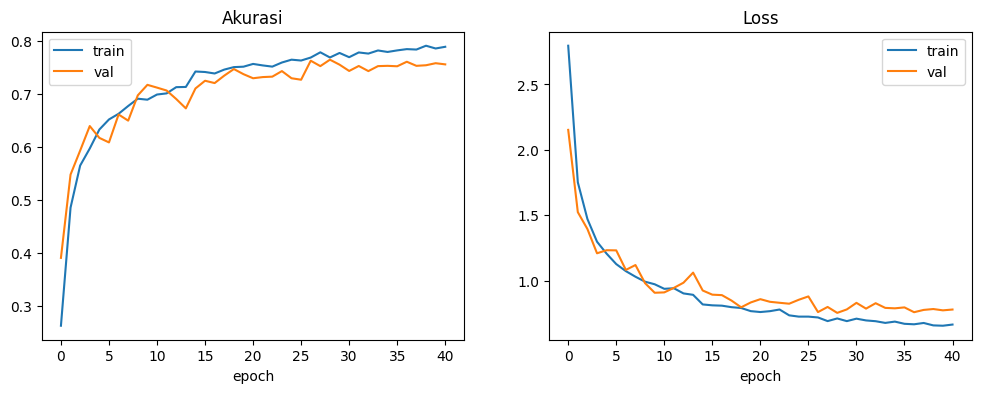

In [ ]:
with open(HISTORY_PATH) as f:
    h = json.load(f)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h["accuracy"], label="train"); ax[0].plot(h["val_accuracy"], label="val")
ax[0].set_title("Akurasi"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(h["loss"], label="train"); ax[1].plot(h["val_loss"], label="val")
ax[1].set_title("Loss"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.show()

## 14. Evaluasi pada Data Test (Bobot Terbaik)
Memuat `best_checkpoint.keras` secara terpisah agar evaluasi dijamin memakai bobot **terbaik**, bukan bobot epoch terakhir.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score

eval_model = keras.models.load_model(BEST_CKPT)

test_loss, test_acc, test_top5 = eval_model.evaluate(test_ds, verbose=0)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f} | Top-5 accuracy: {test_top5:.4f}")

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = np.argmax(eval_model.predict(test_ds, verbose=0), axis=1)
print(f"Macro F1: {f1_score(y_true, y_pred, average='macro'):.4f}\n")
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

Test loss: 0.7417 | Test accuracy: 0.7629 | Top-5 accuracy: 0.9609
Macro F1: 0.7562

              precision    recall  f1-score   support

     1035185       0.83      0.93      0.88        90
     1035195       0.87      0.86      0.87        86
     1035290       0.73      0.86      0.79        71
     1035434       0.71      0.71      0.71        58
     1035551       1.00      0.99      0.99        78
     1035578       0.59      0.96      0.73        72
     1035864       0.71      0.95      0.81        85
     1035931       0.75      0.70      0.72       129
     1036154       0.49      0.41      0.45        81
     1036192       0.55      0.53      0.54        68
     1036216       0.76      0.76      0.76       103
     1036893       0.94      0.93      0.94        71
     4308789       0.77      0.74      0.75        54
     4308806       0.96      0.49      0.65        55
     4308815       0.98      1.00      0.99        60
     4473617       0.60      0.53      0.56       

## 15. Confusion Matrix
Dinormalisasi per baris (proporsi per kelas asli), plus daftar pasangan kelas yang paling sering tertukar.

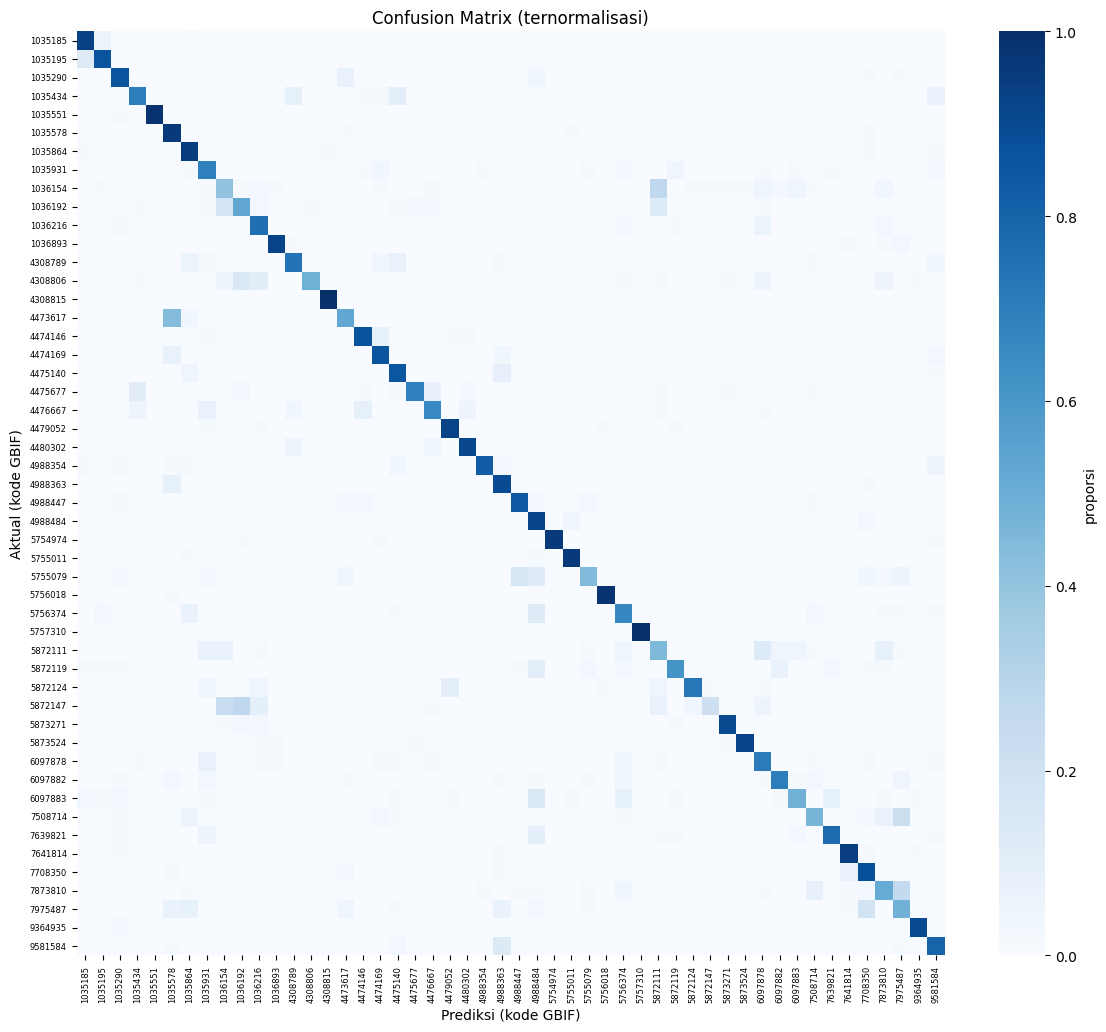

10 kesalahan paling sering (jumlah, aktual -> prediksi):
   27x  7508714 -> 7975487
   23x  4473617 -> 1035578
   22x  1036154 -> 5872111
   20x  7873810 -> 7975487
   16x  5755079 -> 4988447
   15x  5872147 -> 1036192
   13x  5872147 -> 1036154
   12x  7975487 -> 7708350
   12x  5755079 -> 4988484
   12x  1036192 -> 1036154


In [ ]:
import seaborn as sns

cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(class_names)))
cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)

plt.figure(figsize=(14, 12))
sns.heatmap(cm_norm, cmap="Blues", xticklabels=class_names, yticklabels=class_names,
            cbar_kws={"label": "proporsi"})
plt.xticks(fontsize=6, rotation=90); plt.yticks(fontsize=6)
plt.xlabel("Prediksi (kode GBIF)"); plt.ylabel("Aktual (kode GBIF)"); plt.title("Confusion Matrix (ternormalisasi)")
plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted(((off[i, j], class_names[i], class_names[j])
                for i in range(len(off)) for j in range(len(off)) if off[i, j] > 0), reverse=True)[:10]
print("10 kesalahan paling sering (jumlah, aktual -> prediksi):")
for n, a, b in pairs:
    print(f"  {n:>3}x  {a} -> {b}")

## 16. Simpan Model Final & Metadata
- `model_cnn_serangga_final.keras`: salinan dari bobot terbaik, nama lebih jelas untuk dipakai di luar notebook.
- `class_names.json`: mapping indeks -> kode GBIF, salinan `CONFIG` (termasuk `transfer_learning`),
  dan metrik test — **wajib disimpan bersama model** agar urutan label & pipeline preprocessing
  konsisten saat inference.

In [ ]:
FINAL_MODEL_PATH = os.path.join(OUTPUT_DIR, "model_cnn_serangga_final.keras")
shutil.copy2(BEST_CKPT, FINAL_MODEL_PATH)

metadata = {
    "img_size": IMG_SIZE,
    "class_names": class_names,
    "index_to_gbif": {str(i): c for i, c in enumerate(class_names)},
    "gbif_to_name": {},
    "config": CONFIG,
    "test_metrics": {"loss": float(test_loss), "accuracy": float(test_acc), "top5_accuracy": float(test_top5)},
}
with open(CLASS_NAMES_PATH, "w") as f:
    json.dump(metadata, f, indent=2)

print("Tersimpan di:", OUTPUT_DIR)
print(sorted(os.listdir(OUTPUT_DIR)))

Tersimpan di: /content/drive/MyDrive/insect_cnn_effnet_output
['best_checkpoint.keras', 'class_names.json', 'history_log.json', 'last_checkpoint.keras', 'model_cnn_serangga_final.keras']


## 17. (Opsional) Ambil Nama Spesies dari GBIF API
Mengisi `gbif_to_name` agar hasil prediksi berupa nama, bukan hanya kode. Butuh internet; set `FETCH_NAMES = False` untuk melewati.

In [ ]:
FETCH_NAMES = True

if FETCH_NAMES:
    import requests
    for c in class_names:
        try:
            r = requests.get(f"https://api.gbif.org/v1/species/{c}", timeout=10)
            d = r.json()
            metadata["gbif_to_name"][c] = d.get("canonicalName") or d.get("scientificName") or "unknown"
        except Exception:
            metadata["gbif_to_name"][c] = "unknown"
    with open(CLASS_NAMES_PATH, "w") as f:
        json.dump(metadata, f, indent=2)
    print({k: metadata["gbif_to_name"][k] for k in class_names[:5]})

{'1035185': 'Amara aenea', '1035195': 'Amara familiaris', '1035290': 'Loricera pilicornis', '1035434': 'Bradycellus harpalinus', '1035551': 'Elaphrus riparius'}


## 18. Contoh Inference pada Satu Gambar
Gambar diproses dengan **persis** `tf.keras.applications.efficientnet.preprocess_input` yang sama
seperti di pipeline `tf.data` (bagian 9), sehingga skala pikselnya konsisten dengan saat training/evaluasi.
Untuk gambar sendiri, ganti `example_path` dengan path file lain (atau upload via `files.upload()`).

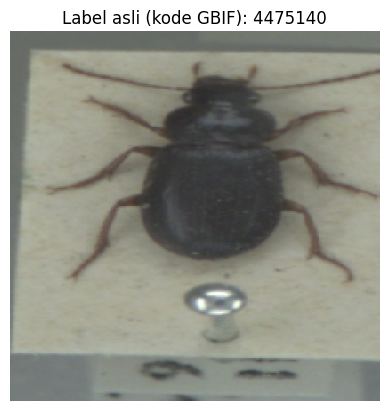

Kode GBIF    4475140 | Ophonus rufibarbis             |  97.9%
Kode GBIF    9581584 | Calathus mollis                |   2.0%
Kode GBIF    4988354 | Calathus melanocephalus        |   0.0%
Kode GBIF    4988363 | Calathus fuscipes              |   0.0%
Kode GBIF    7508714 | Pterostichus strenuus          |   0.0%


In [ ]:
with open(CLASS_NAMES_PATH) as f:
    meta = json.load(f)
inference_model = keras.models.load_model(FINAL_MODEL_PATH)

def predict_image(path, model, meta, top_k=5):
    size = meta["img_size"]
    img = tf.keras.utils.load_img(path, target_size=(size, size))     # utk ditampilkan apa adanya
    arr = tf.keras.utils.img_to_array(img)
    arr = tf.keras.applications.efficientnet.preprocess_input(arr)[None, ...]  # utk input model
    probs = model.predict(arr, verbose=0)[0]
    results = []
    for i in np.argsort(probs)[::-1][:top_k]:
        gbif = meta["index_to_gbif"][str(i)]
        results.append((gbif, meta["gbif_to_name"].get(gbif, "-"), float(probs[i])))
    return img, results

# Contoh: ambil satu gambar acak dari daftar path test
example_idx = random.randrange(len(p_test))
example_path, example_label = p_test[example_idx], y_test[example_idx]

img, results = predict_image(example_path, inference_model, meta)
plt.imshow(img); plt.axis("off"); plt.title(f"Label asli (kode GBIF): {example_label}"); plt.show()
for gbif, name, p in results:
    print(f"Kode GBIF {gbif:>10} | {name:<30} | {p*100:5.1f}%")